# Hybrid CNN–VQC for Alzheimer's disease diagnosis — revised methodology

This notebook re-runs the **CNN**, **VQC** and **hybrid CNN–VQC** models with the revised methodology.
The classifier architecture is unchanged; only the data pipeline, the CNN→quantum interface, the training
procedure and the inference step change. **All three models share the identical pipeline, data split and
epoch budget**, so the comparison stays fair.

| Section | Change |
|---|---|
| 3 | Subject-level indexing and slice-band selection (target the medial temporal lobe) |
| 4 | N4 bias-field correction → skull stripping + QC → per-subject z-score → pad & resize (cached) |
| 5 | Subject-level stratified train / validation / test split (no subject in two sets) |
| 6 | 2.5D input (3 adjacent slices as channels) + training-only augmentation |
| 7 | Models: hybrid CNN–VQC with bounded angle encoding, near-zero VQC init, analytic expectations; CNN-only and VQC-only baselines |
| 8 | Class-weighted (or focal) loss with label smoothing, separate learning rates, warmup + cosine schedule, early stopping on validation AUC |
| 9 | Two-stage hybrid training: CNN pre-training → frozen CNN + VQC → joint fine-tuning |
| 10 | Optional Optuna tuning of training hyperparameters on the validation set |
| 11 | Training of all models (one or more seeds) |
| 12 | Subject-level aggregation, decision-threshold tuning on validation (Youden's J), seed ensembling, metrics with bootstrap 95% CIs |
| 13 | McNemar tests, paired AUC comparison, complexity table |
| 14 | ROC / PR curves, confusion matrices, training curves |
| 15 | Grad-CAM for the hybrid and CNN models |
| 16 | Optional external validation on ADNI |

**Before running**
1. On Kaggle: add the dataset `ninadaithal/imagesoasis`, select a GPU accelerator and switch Internet on (for `pip install`).
2. Set `TASK` in the configuration cell to match the paper (binary or 4-class).
3. If your model differs from the classes in Section 7 (layers, qubits, circuit), paste your exact definitions there so the classifier stays identical to the paper.
4. Run once with `SMOKE_TEST = True` to check the pipeline end to end, then set it to `False` for the real run.

Every number reported in the paper must come from this notebook's actual outputs.

## 1. Setup

In [2]:
%pip install -q pennylane SimpleITK optuna nibabel

Note: you may need to restart the kernel to use updated packages.


In [3]:
import os, re, json, time, math, random, hashlib, warnings
from pathlib import Path
from collections import defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from joblib import Parallel, delayed
from scipy import ndimage as ndi
from scipy.stats import binomtest
from skimage.filters import threshold_otsu
from skimage.measure import label as cc_label
from skimage.morphology import disk
from skimage.transform import resize
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, precision_recall_curve,
                             average_precision_score, confusion_matrix)

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
import torchvision.transforms as T

import SimpleITK as sitk
import pennylane as qml

warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("torch", torch.__version__, "| pennylane", qml.__version__, "| device", DEVICE)

torch 2.11.0+cu128 | pennylane 0.45.1 | device cuda


## 2. Configuration

In [4]:
# ============================ CONFIGURATION ============================
SMOKE_TEST = False          # True = tiny, fast run to check the pipeline end to end

DATA_DIR = None             # None = auto-detect the Kaggle OASIS folder with the class sub-folders
WORK_DIR = Path("/kaggle/working") if Path("/kaggle/working").exists() else Path("./work")
CACHE_DIR = WORK_DIR / "cache"
OUT_DIR = WORK_DIR / "outputs"

# "binary"     = Non Demented (CN) vs Demented (all three dementia folders merged)
# "multiclass" = the four Kaggle classes
# Set this to match the paper.
TASK = "binary"

# --- Slice selection (Section 3) ---
# Set SLICE_INDEX_RANGE to the filename slice indices that show the hippocampus /
# medial temporal lobe (use the montage in Section 3). None = use the central
# fraction of each scan's available slices given by SLICE_FRACTION_RANGE.
SLICE_INDEX_RANGE = None            # e.g. (115, 145)
SLICE_FRACTION_RANGE = (0.25, 0.75)

# --- Preprocessing (Section 4) ---
APPLY_N4 = True
SKULL_STRIP = True                  # replace skull_strip() with your Figure S5 method if different
QC_MASK_AREA_RANGE = (0.05, 0.75)   # accepted brain-mask area (fraction of the image)
IMG_SIZE = 128
USE_2P5D = True                     # 3 adjacent slices as the 3 input channels
N_JOBS = -1                         # parallel preprocessing workers

# --- Augmentation (training only; no left-right flips because atrophy can be asymmetric) ---
AUG_ROT_DEG = 10
AUG_TRANSLATE = 0.05
AUG_SCALE = (0.95, 1.05)
AUG_INTENSITY = 0.10

# --- Split ---
TEST_FRAC, VAL_FRAC = 0.15, 0.15
SPLIT_SEED = 42

# --- Classifier (keep identical to the paper) ---
N_QUBITS = 8
N_VQC_LAYERS = 4
CNN_WIDTHS = (32, 64, 128, 256)
VQC_INIT_STD = 0.01                 # near-zero initialisation of the VQC rotations

# --- Training ---
BATCH_SIZE = 64
NUM_WORKERS = 2
EPOCHS_STAGE_A = 15     # hybrid stage A: CNN + temporary classical head
EPOCHS_STAGE_B = 10     # hybrid stage B: frozen CNN, train interface + VQC + output head
EPOCHS_STAGE_C = 10     # hybrid stage C: joint fine-tuning
# The CNN-only and VQC-only baselines get the same total budget (A + B + C epochs).
WARMUP_EPOCHS = 2
PATIENCE = 5            # early stopping on validation AUC
HP_DEFAULT = dict(
    lr_cnn=1e-3,           # CNN trained from scratch (hybrid stage A, CNN-only)
    lr_cnn_finetune=1e-4,  # CNN during joint fine-tuning (hybrid stage C)
    lr_classical=1e-3,     # dense interface and output head
    lr_quantum=1e-2,       # VQC rotation parameters
    weight_decay=1e-4,
    dropout=0.3,
    label_smoothing=0.05,
)
LOSS = "weighted_ce"       # "weighted_ce" or "focal"
FOCAL_GAMMA = 2.0
BALANCED_SAMPLER = False   # True = class-balanced batches (class weights in the loss are then switched off)
SEEDS = [42]               # several seeds -> probability-averaged ensemble, e.g. [42, 7, 123]

# --- Optional steps ---
RUN_OPTUNA = False
OPTUNA_TRIALS = 20
OPTUNA_EPOCH_SCALE = 0.4   # fraction of the epoch budget used per trial
N_BOOTSTRAP = 1000
RUN_GRADCAM = True
RUN_ADNI = False
ADNI_DIR = None            # folder with AD/ and CN/ sub-folders of NIfTI scans (.nii / .nii.gz)

if SMOKE_TEST:
    IMG_SIZE, N_QUBITS, N_VQC_LAYERS = 32, 4, 1
    CNN_WIDTHS = (8, 16)
    EPOCHS_STAGE_A = EPOCHS_STAGE_B = EPOCHS_STAGE_C = 1
    WARMUP_EPOCHS, PATIENCE, BATCH_SIZE, NUM_WORKERS = 0, 1, 16, 0
    N_BOOTSTRAP, OPTUNA_TRIALS = 30, 2
    SEEDS = [42, 7]
SMOKE_SUBJECTS_PER_CLASS = 4

for d in (CACHE_DIR, OUT_DIR):
    d.mkdir(parents=True, exist_ok=True)

def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(SPLIT_SEED)

## 3. Data indexing and slice selection

Each image is indexed by subject (`OAS1_XXXX`), scan (session + acquisition) and slice number, so that
all later steps can work per subject. Re-scans of the same subject (MR2) are grouped under that subject.

In [5]:
CLASS_ORDER = ["Non Demented", "Very mild Dementia", "Mild Dementia", "Moderate Dementia"]

def find_data_dir():
    wanted = {c.lower() for c in CLASS_ORDER}
    for root in (Path("/kaggle/input"), Path.cwd()):
        if not root.exists():
            continue
        for dirpath, dirnames, _ in os.walk(root):
            names = {d.lower() for d in dirnames}
            if "non demented" in names and len(wanted & names) >= 2:
                return Path(dirpath)
    raise FileNotFoundError("Could not find the OASIS class folders; set DATA_DIR in the configuration cell.")

FNAME_RE = re.compile(r"(OAS1_\d{4})_(MR\d+)_mpr-(\d+)_(\d+)", re.I)

def parse_name(stem):
    m = FNAME_RE.search(stem)
    if m:
        subj, sess, mpr, sl = m.groups()
        return subj.upper(), f"{subj.upper()}_{sess.upper()}_mpr-{mpr}", int(sl)
    subj = re.search(r"OAS1_\d{4}", stem, re.I)
    nums = re.findall(r"\d+", stem)
    if subj is None or not nums:
        return None
    scan = stem[: stem.rfind(nums[-1])].rstrip("_- ")
    return subj.group(0).upper(), scan, int(nums[-1])

data_dir = Path(DATA_DIR) if DATA_DIR else find_data_dir()
print("Data folder:", data_dir)
folders = {d.name.lower(): d for d in data_dir.iterdir() if d.is_dir()}
rows = []
for cname in CLASS_ORDER:
    d = folders.get(cname.lower())
    if d is None:
        print("Class folder not found:", cname)
        continue
    for f in d.iterdir():
        if f.suffix.lower() not in {".jpg", ".jpeg", ".png"}:
            continue
        parsed = parse_name(f.stem)
        if parsed is not None:
            rows.append((str(f), cname, *parsed))
df_all = pd.DataFrame(rows, columns=["path", "class_name", "subject", "scan", "slice"])

if TASK == "binary":
    CLASS_NAMES = ["CN (Non Demented)", "Demented"]
    df_all["label"] = (df_all.class_name != "Non Demented").astype(int)
else:
    CLASS_NAMES = [c for c in CLASS_ORDER if c in set(df_all.class_name)]
    df_all["label"] = df_all.class_name.map({c: i for i, c in enumerate(CLASS_NAMES)})
N_CLASSES = len(CLASS_NAMES)

# a subject must carry a single label
conflict = df_all.groupby("subject").label.nunique()
conflict = conflict[conflict > 1].index
if len(conflict):
    print(f"Dropping {len(conflict)} subject(s) with conflicting labels")
    df_all = df_all[~df_all.subject.isin(conflict)]

if SMOKE_TEST:
    subj_tab = df_all.drop_duplicates("subject")[["subject", "label"]]
    keep = []
    for _, g in subj_tab.groupby("label"):
        keep += list(g.subject.sample(min(len(g), SMOKE_SUBJECTS_PER_CLASS), random_state=0))
    df_all = df_all[df_all.subject.isin(keep)]

summary = (df_all.groupby("class_name")
           .agg(images=("path", "size"), scans=("scan", "nunique"), subjects=("subject", "nunique"))
           .reindex([c for c in CLASS_ORDER if c in set(df_all.class_name)]))
print(summary.to_string())
print("Classes used:", CLASS_NAMES)
for lab, n in df_all.groupby("label").subject.nunique().items():
    if n < 5:
        tip = " Consider TASK='binary' or merging small classes." if TASK == "multiclass" else ""
        print(f"WARNING: '{CLASS_NAMES[lab]}' has only {n} subject(s); a subject-level split cannot "
              f"evaluate it reliably.{tip}")

Data folder: /kaggle/input/datasets/ninadaithal/imagesoasis/Data
                    images  scans  subjects
class_name                                 
Non Demented         67222   1102       266
Very mild Dementia   13725    225        58
Mild Dementia         5002     82        21
Moderate Dementia      488      8         2
Classes used: ['CN (Non Demented)', 'Demented']


1417 scans, 43927 band slices selected


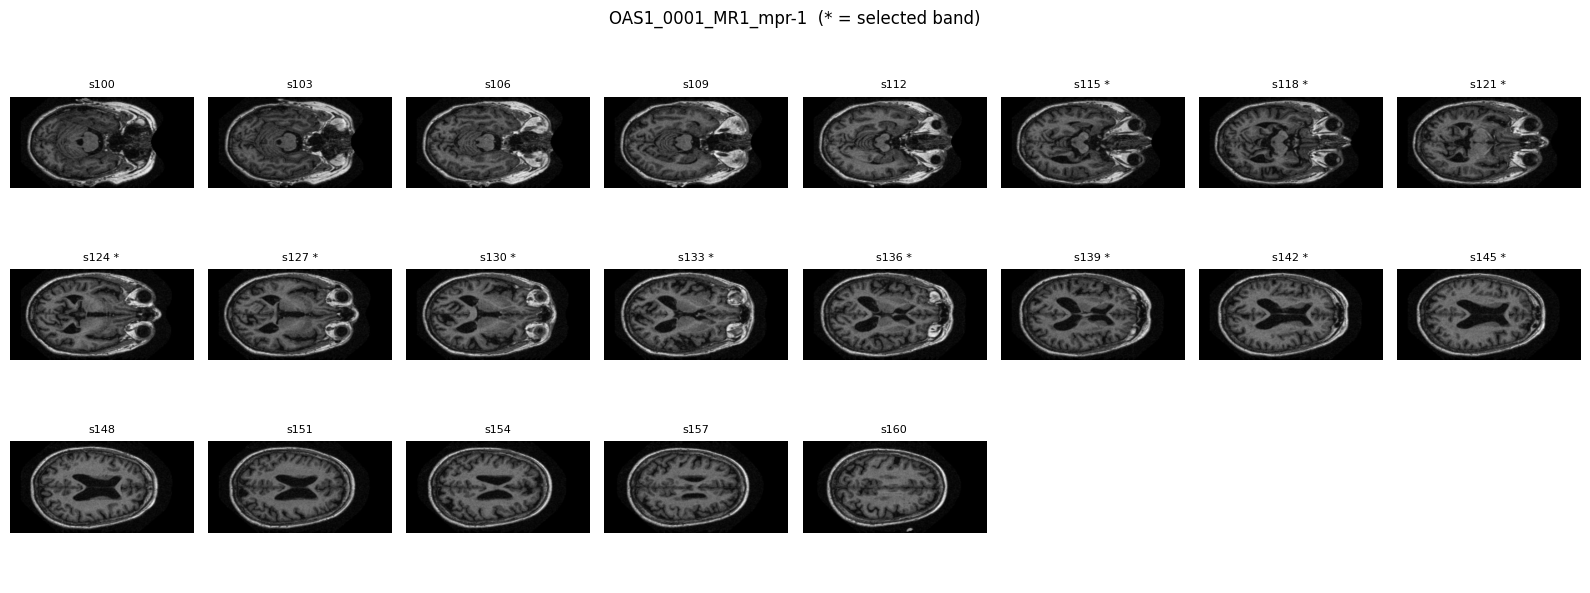

In [7]:
def select_band(slices):
    s = np.sort(np.unique(slices))
    if SLICE_INDEX_RANGE is not None:
        lo, hi = SLICE_INDEX_RANGE
        return s, s[(s >= lo) & (s <= hi)]
    a, b = SLICE_FRACTION_RANGE
    n = len(s)
    return s, s[int(round(a * (n - 1))): int(round(b * (n - 1))) + 1]

# scan -> slices to load (band plus one neighbour each side for 2.5D) and the band positions
scan_plan = {}
for scan, g in df_all.groupby("scan"):
    g = g.sort_values("slice").drop_duplicates("slice")
    s_all, band = select_band(g.slice.values)
    if len(band) == 0:
        continue
    i0, i1 = np.searchsorted(s_all, band[0]), np.searchsorted(s_all, band[-1])
    lo, hi = max(i0 - 1, 0), min(i1 + 1, len(s_all) - 1)
    load = s_all[lo:hi + 1]
    by_slice = dict(zip(g.slice, g.path))
    scan_plan[scan] = dict(subject=g.subject.iloc[0], label=int(g.label.iloc[0]),
                           slices=[int(x) for x in load], paths=[by_slice[x] for x in load],
                           center=[int(np.where(load == b)[0][0]) for b in band])
n_center = sum(len(p["center"]) for p in scan_plan.values())
print(f"{len(scan_plan)} scans, {n_center} band slices selected")

def show_scan_montage(scan_id, step=3, cols=8):
    g = df_all[df_all.scan == scan_id].sort_values("slice").iloc[::step]
    rows_ = math.ceil(len(g) / cols)
    fig, axes = plt.subplots(rows_, cols, figsize=(2 * cols, 2 * rows_))
    for ax in np.ravel(axes):
        ax.axis("off")
    band = set(scan_plan[scan_id]["slices"])
    for ax, (_, r) in zip(np.ravel(axes), g.iterrows()):
        ax.imshow(Image.open(r.path).convert("L"), cmap="gray")
        ax.set_title(f"s{r.slice}" + (" *" if r.slice in band else ""), fontsize=8)
    fig.suptitle(f"{scan_id}  (* = selected band)")
    plt.tight_layout(); plt.show()

# Inspect one scan and set SLICE_INDEX_RANGE to the slices showing the hippocampus.
show_scan_montage(next(iter(scan_plan)))

## 4. Preprocessing: N4 → skull stripping + QC → per-subject z-score → resize

Results are cached per scan, so this runs once. N4 on tens of thousands of slices takes a while; it runs in
parallel and the cache key changes automatically when a preprocessing setting changes.

`skull_strip()` below is a simple morphological method. If Figure S5 was produced with a different method,
paste it in here so the preprocessing matches the paper.

In [8]:
def load_gray(path):
    return np.asarray(Image.open(path).convert("L"), dtype=np.float32)

def n4_correct(img, shrink=2):
    try:
        sitk.ProcessObject_SetGlobalDefaultNumberOfThreads(1)
        image = sitk.GetImageFromArray(img.astype(np.float32))
        mask = sitk.OtsuThreshold(image, 0, 1, 200)
        small = sitk.Shrink(image, [shrink] * image.GetDimension())
        small_mask = sitk.Shrink(mask, [shrink] * image.GetDimension())
        corrector = sitk.N4BiasFieldCorrectionImageFilter()
        corrector.SetMaximumNumberOfIterations([20, 20, 20])
        corrector.Execute(small, small_mask)
        log_bias = corrector.GetLogBiasFieldAsImage(image)
        return sitk.GetArrayFromImage(image / sitk.Exp(log_bias)).astype(np.float32)
    except Exception:
        return img  # blank or degenerate slice

def skull_strip(img, erode_r=4):
    # Simple 2D skull stripping: Otsu head mask -> erosion detaches skull/scalp ->
    # largest component -> dilation and hole filling.
    fg = img[img > 0]
    if fg.size < 100:
        return img * 0, np.zeros(img.shape, bool)
    m = img > threshold_otsu(fg)
    m = ndi.binary_opening(m, structure=disk(2))
    m = ndi.binary_erosion(m, structure=disk(erode_r))
    lab = cc_label(m)
    if lab.max() == 0:
        return img * 0, np.zeros(img.shape, bool)
    m = lab == (np.argmax(np.bincount(lab.ravel())[1:]) + 1)
    m = ndi.binary_fill_holes(ndi.binary_dilation(m, structure=disk(erode_r)))
    return img * m, m

def pad_square_resize(img, size):
    h, w = img.shape
    s = max(h, w)
    out = np.zeros((s, s), np.float32)
    y0, x0 = (s - h) // 2, (s - w) // 2
    out[y0:y0 + h, x0:x0 + w] = img
    return resize(out, (size, size), order=1, anti_aliasing=True, preserve_range=True).astype(np.float32)

def preprocess_slices(images):
    # images: list of 2D arrays from one scan -> (volume float16 [n, S, S], qc flags)
    imgs, masks = [], []
    for img in images:
        if APPLY_N4:
            img = n4_correct(img)
        if SKULL_STRIP:
            img, m = skull_strip(img)
        else:
            fg = img[img > 0]
            m = img > (threshold_otsu(fg) if fg.size > 100 else 0)
        imgs.append(img); masks.append(m)
    brain = np.concatenate([i[m] for i, m in zip(imgs, masks)])
    mu, sd = (float(brain.mean()), float(brain.std()) + 1e-6) if brain.size else (0.0, 1.0)
    vol, qc = [], []
    for img, m in zip(imgs, masks):
        z = np.where(m, np.clip((img - mu) / sd, -5, 5), 0.0)   # per-subject (per-scan) z-score
        vol.append(pad_square_resize(z, IMG_SIZE))
        qc.append(bool(QC_MASK_AREA_RANGE[0] <= m.mean() <= QC_MASK_AREA_RANGE[1]))
    return np.stack(vol).astype(np.float16), qc

PREP_KEY = hashlib.md5(json.dumps(dict(n4=APPLY_N4, ss=SKULL_STRIP, size=IMG_SIZE, qc=QC_MASK_AREA_RANGE,
                                       idx=SLICE_INDEX_RANGE, frac=SLICE_FRACTION_RANGE),
                                  default=str).encode()).hexdigest()[:10]
PREP_DIR = CACHE_DIR / f"prep_{PREP_KEY}"
PREP_DIR.mkdir(parents=True, exist_ok=True)

def preprocess_scan(scan, plan):
    out = PREP_DIR / f"{scan}.npz"
    if out.exists():
        with np.load(out) as z:
            return scan, z["qc"].tolist()
    vol, qc = preprocess_slices([load_gray(p) for p in plan["paths"]])
    np.savez_compressed(out, vol=vol, qc=np.array(qc))
    return scan, qc

t0 = time.time()
qc_map = dict(Parallel(n_jobs=N_JOBS, backend="loky", verbose=1)(
    delayed(preprocess_scan)(s, p) for s, p in scan_plan.items()))
VOLUMES = {}
for s in scan_plan:
    with np.load(PREP_DIR / f"{s}.npz") as z:
        VOLUMES[s] = z["vol"]
print(f"Preprocessing done in {time.time() - t0:.0f}s")

n_pass = sum(qc_map[s][k] for s, p in scan_plan.items() for k in p["center"])
print(f"Brain mask accepted on {100 * n_pass / n_center:.1f}% of selected slices ({n_pass}/{n_center})")

rows = [(s, k, p["slices"][k], p["subject"], p["label"])
        for s, p in scan_plan.items() for k in p["center"] if qc_map[s][k]]
samples = pd.DataFrame(rows, columns=["scan", "pos", "slice", "subject", "label"])

[Parallel(n_jobs=-1)]: Using backend LokyBackend with 4 concurrent workers.
[Parallel(n_jobs=-1)]: Done  42 tasks      | elapsed:  2.6min
[Parallel(n_jobs=-1)]: Done 192 tasks      | elapsed:  9.4min
[Parallel(n_jobs=-1)]: Done 442 tasks      | elapsed: 21.1min
[Parallel(n_jobs=-1)]: Done 792 tasks      | elapsed: 37.4min
[Parallel(n_jobs=-1)]: Done 1242 tasks      | elapsed: 57.3min
[Parallel(n_jobs=-1)]: Done 1417 out of 1417 | elapsed: 65.1min finished


Preprocessing done in 3912s
Brain mask accepted on 73.1% of selected slices (32097/43927)


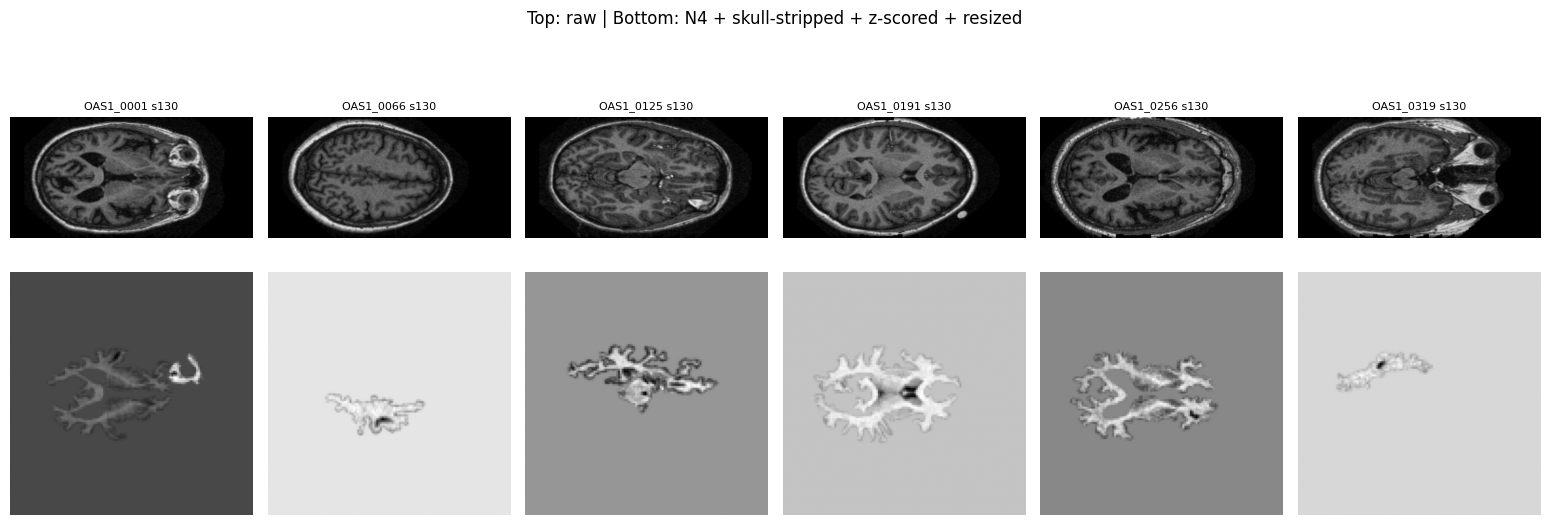

In [9]:
# Visual check: raw slice vs preprocessed slice for a few scans
show = list(scan_plan)[:: max(1, len(scan_plan) // 6)][:6]
fig, axes = plt.subplots(2, len(show), figsize=(2.6 * len(show), 5.4))
axes = np.array(axes).reshape(2, -1)
for j, s in enumerate(show):
    k = scan_plan[s]["center"][len(scan_plan[s]["center"]) // 2]
    axes[0, j].imshow(load_gray(scan_plan[s]["paths"][k]), cmap="gray")
    axes[1, j].imshow(VOLUMES[s][k].astype(np.float32), cmap="gray")
    axes[0, j].set_title(f"{scan_plan[s]['subject']} s{scan_plan[s]['slices'][k]}", fontsize=8)
for ax in axes.ravel():
    ax.axis("off")
axes[0, 0].set_ylabel("raw"); axes[1, 0].set_ylabel("preprocessed")
plt.suptitle("Top: raw | Bottom: N4 + skull-stripped + z-scored + resized")
plt.tight_layout(); plt.savefig(OUT_DIR / "preprocessing_examples.png", dpi=200); plt.show()

## 5. Subject-level stratified split

Subjects (not slices) are assigned to train, validation and test, stratified by class, so no brain
appears in more than one set. The same split is saved and used for every model.

In [10]:
def stratified_subject_split(samples, test_frac, val_frac, seed):
    rng = np.random.RandomState(seed)
    subj = samples.drop_duplicates("subject")[["subject", "label"]]
    assign = {}
    for lab, g in subj.groupby("label"):
        s = g.subject.values.copy(); rng.shuffle(s); n = len(s)
        n_test, n_val = int(round(n * test_frac)), int(round(n * val_frac))
        if n >= 3:
            n_test, n_val = max(n_test, 1), max(n_val, 1)
        elif n == 2:
            n_test, n_val = 1, 0
        else:
            n_test, n_val = 0, 0
        for x in s[:n_test]: assign[x] = "test"
        for x in s[n_test:n_test + n_val]: assign[x] = "val"
        for x in s[n_test + n_val:]: assign[x] = "train"
    return samples.subject.map(assign)

samples["split"] = stratified_subject_split(samples, TEST_FRAC, VAL_FRAC, SPLIT_SEED)
sets = {s: set(samples.subject[samples.split == s]) for s in ("train", "val", "test")}
assert not (sets["train"] & sets["val"] or sets["train"] & sets["test"] or sets["val"] & sets["test"])
DF = {s: samples[samples.split == s].reset_index(drop=True) for s in ("train", "val", "test")}
samples.to_csv(OUT_DIR / "split_samples.csv", index=False)

tab = samples.groupby(["split", "label"]).agg(subjects=("subject", "nunique"), slices=("slice", "size")).unstack("label")
tab.columns = [f"{a} | {CLASS_NAMES[b]}" for a, b in tab.columns]
print(tab.reindex(["train", "val", "test"]).to_string())

       subjects | CN (Non Demented)  subjects | Demented  slices | CN (Non Demented)  slices | Demented
split                                                                                                  
train                           180                   54                       18320               4202
val                              38                   12                        3974               1217
test                             38                   12                        3596                788


## 6. 2.5D input and augmentation

Each sample stacks the selected slice with its two neighbours as 3 channels. Augmentation (small rotation,
translation, scaling, intensity jitter inside the brain) is applied to the training set only.

Training class weights: [0.615 2.68 ]


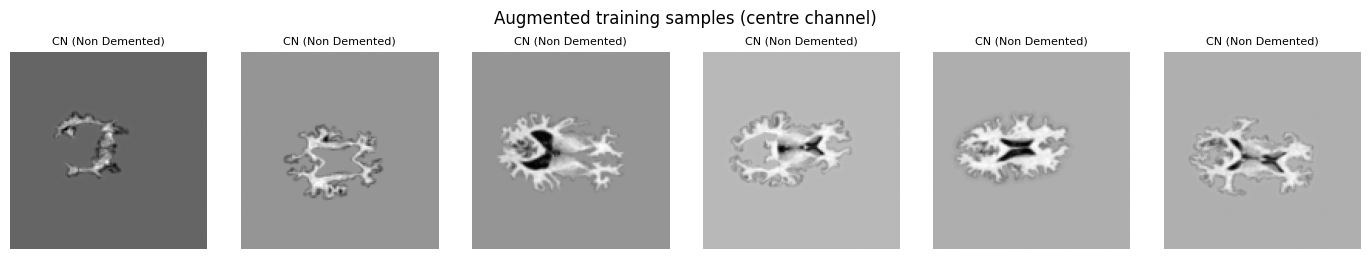

In [11]:
IN_CH = 3 if USE_2P5D else 1

class SliceDataset(Dataset):
    def __init__(self, df, augment=False):
        self.volumes = VOLUMES
        self.scan, self.pos = df.scan.values, df.pos.values
        self.y = df.label.values.astype(np.int64)
        self.augment = augment
        self.affine = T.RandomAffine(degrees=AUG_ROT_DEG, translate=(AUG_TRANSLATE, AUG_TRANSLATE),
                                     scale=AUG_SCALE, interpolation=T.InterpolationMode.BILINEAR, fill=0.0)

    def __len__(self):
        return len(self.y)

    def __getitem__(self, i):
        vol, k = self.volumes[self.scan[i]], int(self.pos[i])
        if USE_2P5D:
            x = vol[[max(k - 1, 0), k, min(k + 1, len(vol) - 1)]]
        else:
            x = vol[k:k + 1]
        x = torch.from_numpy(x.astype(np.float32))
        if self.augment:
            x = self.affine(x)
            gain = 1 + AUG_INTENSITY * (2 * torch.rand(1) - 1)
            shift = AUG_INTENSITY * (2 * torch.rand(1) - 1)
            x = torch.where(x != 0, x * gain + shift, x)
        return x, self.y[i]

def class_weights_from(df):
    counts = np.bincount(df.label.values, minlength=N_CLASSES).astype(float)
    w = counts.sum() / (N_CLASSES * np.maximum(counts, 1))
    w[counts == 0] = 0.0
    return torch.tensor(w, dtype=torch.float32)

def make_loaders(seed):
    g = torch.Generator(); g.manual_seed(seed)
    ds_tr = SliceDataset(DF["train"], augment=True)
    if BALANCED_SAMPLER:
        w = class_weights_from(DF["train"]).numpy()[DF["train"].label.values]
        sampler = WeightedRandomSampler(torch.tensor(w, dtype=torch.double), len(w), replacement=True, generator=g)
        dl_tr = DataLoader(ds_tr, BATCH_SIZE, sampler=sampler, num_workers=NUM_WORKERS, drop_last=True)
    else:
        dl_tr = DataLoader(ds_tr, BATCH_SIZE, shuffle=True, generator=g, num_workers=NUM_WORKERS, drop_last=True)
    kw = dict(batch_size=BATCH_SIZE * 2, shuffle=False, num_workers=NUM_WORKERS)
    return dl_tr, DataLoader(SliceDataset(DF["val"]), **kw), DataLoader(SliceDataset(DF["test"]), **kw)

print("Training class weights:", class_weights_from(DF["train"]).numpy().round(3))

# augmentation preview
ds_prev = SliceDataset(DF["train"], augment=True)
fig, axes = plt.subplots(1, 6, figsize=(14, 2.6))
for j, ax in enumerate(axes):
    x, y = ds_prev[j * max(1, len(ds_prev) // 6)]
    ax.imshow(x[x.shape[0] // 2], cmap="gray"); ax.set_title(CLASS_NAMES[y], fontsize=8); ax.axis("off")
plt.suptitle("Augmented training samples (centre channel)"); plt.tight_layout(); plt.show()

## 7. Models

* **Hybrid CNN–VQC**: CNN feature extractor → dense reduction to `N_QUBITS` features → BatchNorm →
  bounded angles `π·sigmoid(x)` ∈ [0, π] → angle encoding (RY) → variational layers (RY/RZ + CNOT ring) →
  Pauli-Z expectations → dense + softmax.
* **CNN-only**: the same CNN feature extractor → dense + softmax.
* **VQC-only**: pooled image → dense projection to `N_QUBITS` angles → the same VQC → dense + softmax.

The VQC runs on PennyLane's `default.qubit` simulator with analytic expectation values (no shot noise)
and backpropagation. It stays on the CPU; the rest of the model uses the GPU.

`temp_head` is used only during hybrid stage A and is not part of the final classifier.

**If your paper's architecture differs, replace these classes with your exact definitions.**

In [12]:
def conv_block(cin, cout):
    return nn.Sequential(
        nn.Conv2d(cin, cout, 3, padding=1, bias=False), nn.BatchNorm2d(cout), nn.ReLU(inplace=True),
        nn.Conv2d(cout, cout, 3, padding=1, bias=False), nn.BatchNorm2d(cout), nn.ReLU(inplace=True),
        nn.MaxPool2d(2))

class CNNBackbone(nn.Module):
    def __init__(self, in_ch, widths=None):
        super().__init__()
        widths = widths or CNN_WIDTHS
        layers, c = [], in_ch
        for w in widths:
            layers.append(conv_block(c, w)); c = w
        self.features = nn.Sequential(*layers)
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.out_dim = c

    def forward(self, x):
        return self.pool(self.features(x)).flatten(1)

def make_vqc(n_qubits=None, n_layers=None):
    n_qubits, n_layers = n_qubits or N_QUBITS, n_layers or N_VQC_LAYERS
    dev = qml.device("default.qubit", wires=n_qubits)   # analytic expectations, no shots

    @qml.qnode(dev, interface="torch", diff_method="backprop")
    def circuit(inputs, weights):
        qml.AngleEmbedding(inputs, wires=range(n_qubits), rotation="Y")
        for l in range(n_layers):
            for q in range(n_qubits):
                qml.RY(weights[l, q, 0], wires=q)
                qml.RZ(weights[l, q, 1], wires=q)
            for q in range(n_qubits):
                qml.CNOT(wires=[q, (q + 1) % n_qubits])
        return [qml.expval(qml.PauliZ(q)) for q in range(n_qubits)]

    init = lambda t: nn.init.normal_(t, 0.0, VQC_INIT_STD)
    layer = qml.qnn.TorchLayer(circuit, {"weights": (n_layers, n_qubits, 2)}, init_method={"weights": init})
    return layer, circuit

class QuantumBlock(nn.Module):
    # Runs the VQC on the CPU simulator and returns the result on the input's device.
    def __init__(self):
        super().__init__()
        self.qlayer, _ = make_vqc()

    def forward(self, theta):
        z = self.qlayer(theta.float().cpu())
        return z.to(device=theta.device, dtype=theta.dtype)

class AngleInterface(nn.Module):
    # Dense reduction to n_qubits features -> BatchNorm -> bounded angles in [0, pi]
    def __init__(self, in_dim, dropout):
        super().__init__()
        self.net = nn.Sequential(nn.Dropout(dropout), nn.Linear(in_dim, N_QUBITS), nn.BatchNorm1d(N_QUBITS))

    def forward(self, f):
        return math.pi * torch.sigmoid(self.net(f))

class HybridCNNVQC(nn.Module):
    def __init__(self, n_classes, dropout=0.3):
        super().__init__()
        self.backbone = CNNBackbone(IN_CH)
        self.temp_head = nn.Sequential(nn.Dropout(dropout), nn.Linear(self.backbone.out_dim, n_classes))
        self.interface = AngleInterface(self.backbone.out_dim, dropout)
        self.vqc = QuantumBlock()
        self.head = nn.Linear(N_QUBITS, n_classes)   # softmax is applied in the loss and at inference
        self.use_temp_head = False

    def forward(self, x):
        f = self.backbone(x)
        if self.use_temp_head:
            return self.temp_head(f)
        return self.head(self.vqc(self.interface(f)))

class CNNOnly(nn.Module):
    def __init__(self, n_classes, dropout=0.3):
        super().__init__()
        self.backbone = CNNBackbone(IN_CH)
        self.head = nn.Sequential(nn.Dropout(dropout), nn.Linear(self.backbone.out_dim, n_classes))

    def forward(self, x):
        return self.head(self.backbone(x))

class VQCOnly(nn.Module):
    def __init__(self, n_classes, dropout=0.3, pool=8):
        super().__init__()
        self.pool = nn.AdaptiveAvgPool2d(pool)
        self.interface = AngleInterface(IN_CH * pool * pool, dropout)
        self.vqc = QuantumBlock()
        self.head = nn.Linear(N_QUBITS, n_classes)

    def forward(self, x):
        return self.head(self.vqc(self.interface(self.pool(x).flatten(1))))

MODEL_NAMES = ["CNN", "VQC", "Hybrid"]
DISPLAY = {"CNN": "CNN", "VQC": "VQC", "Hybrid": "Hybrid CNN–VQC"}
MODEL_BUILDERS = {"CNN": CNNOnly, "VQC": VQCOnly, "Hybrid": HybridCNNVQC}

def to_device(model):
    model.to(DEVICE)
    for m in model.modules():
        if isinstance(m, QuantumBlock):
            m.to("cpu")   # the PennyLane simulator runs on CPU
    return model

def count_params(model):
    total = sum(p.numel() for n, p in model.named_parameters() if not n.startswith("temp_head"))
    quantum = sum(p.numel() for m in model.modules() if isinstance(m, QuantumBlock) for p in m.parameters())
    return total, quantum

def circuit_depth():
    try:
        _, circ = make_vqc()
        specs = qml.specs(circ)(torch.zeros(N_QUBITS), torch.zeros(N_VQC_LAYERS, N_QUBITS, 2))
        res = specs["resources"]
        return int(res.depth if hasattr(res, "depth") else res["depth"])
    except Exception:
        return "n/a"

x_dummy = torch.randn(4, IN_CH, IMG_SIZE, IMG_SIZE, device=DEVICE)
for name in MODEL_NAMES:
    m = to_device(MODEL_BUILDERS[name](N_CLASSES)).eval()
    with torch.no_grad():
        out = m(x_dummy)
    total, quantum = count_params(m)
    print(f"{DISPLAY[name]:16s} output {tuple(out.shape)} | params {total:,} (quantum {quantum})")
print("VQC circuit depth:", circuit_depth())

CNN              output (4, 2) | params 1,173,730 (quantum 0)
VQC              output (4, 2) | params 1,642 (quantum 64)
Hybrid CNN–VQC   output (4, 2) | params 1,175,370 (quantum 64)
VQC circuit depth: 41


## 8. Training utilities

Class-weighted cross-entropy (or focal loss) with label smoothing, AdamW with separate learning rates per
parameter group, linear warmup + cosine decay, gradient clipping, and early stopping on validation AUC
(the best checkpoint is restored at the end of every stage).

In [13]:
class FocalLoss(nn.Module):
    def __init__(self, weight=None, gamma=2.0, label_smoothing=0.0):
        super().__init__()
        self.weight, self.gamma, self.ls = weight, gamma, label_smoothing

    def forward(self, logits, y):
        ce = F.cross_entropy(logits, y, weight=self.weight, reduction="none", label_smoothing=self.ls)
        pt = torch.softmax(logits, 1).gather(1, y[:, None]).squeeze(1)
        return ((1 - pt) ** self.gamma * ce).mean()

def make_criterion(hp):
    w = None if BALANCED_SAMPLER else class_weights_from(DF["train"]).to(DEVICE)
    if LOSS == "focal":
        return FocalLoss(w, FOCAL_GAMMA, hp["label_smoothing"])
    return nn.CrossEntropyLoss(weight=w, label_smoothing=hp["label_smoothing"])

def warmup_cosine(optimizer, total_steps, warmup_steps):
    def f(step):
        if warmup_steps > 0 and step < warmup_steps:
            return (step + 1) / warmup_steps
        prog = (step - warmup_steps) / max(1, total_steps - warmup_steps)
        return 0.5 * (1 + math.cos(math.pi * min(prog, 1.0)))
    return torch.optim.lr_scheduler.LambdaLR(optimizer, f)

@torch.no_grad()
def predict(model, loader):
    model.eval()
    return torch.cat([torch.softmax(model(x.to(DEVICE)), 1).cpu() for x, _ in loader]).numpy()

def safe_auc(y, probs):
    y = np.asarray(y)
    if probs.shape[1] == 2:
        return roc_auc_score(y, probs[:, 1]) if len(np.unique(y)) == 2 else float("nan")
    aucs = [roc_auc_score(y == c, probs[:, c]) for c in range(probs.shape[1]) if 0 < (y == c).sum() < len(y)]
    return float(np.mean(aucs)) if aucs else float("nan")

def val_score(model, dl_va):
    p = predict(model, dl_va)
    y = dl_va.dataset.y
    auc, acc = safe_auc(y, p), accuracy_score(y, p.argmax(1))
    return (acc if np.isnan(auc) else auc), auc, acc

def params_of(*modules):
    return [p for m in modules for p in m.parameters()]

def set_requires_grad(module, flag):
    for p in module.parameters():
        p.requires_grad = flag

def train_stage(model, param_groups, epochs, dl_tr, dl_va, hp, tag, history, freeze_backbone=False):
    if epochs <= 0:
        return history
    opt = torch.optim.AdamW(param_groups, weight_decay=hp["weight_decay"])
    sched = warmup_cosine(opt, epochs * len(dl_tr), min(WARMUP_EPOCHS, epochs - 1) * len(dl_tr))
    crit = make_criterion(hp)
    best, _, _ = val_score(model, dl_va)          # starting point, so a stage never ends worse than it began
    best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
    bad = 0
    for ep in range(epochs):
        model.train()
        if freeze_backbone:
            model.backbone.eval()                 # keep frozen BatchNorm statistics fixed
        t0, tot, n = time.time(), 0.0, 0
        for x, y in dl_tr:
            x, y = x.to(DEVICE), y.to(DEVICE)
            loss = crit(model(x), y)
            opt.zero_grad(set_to_none=True)
            loss.backward()
            torch.nn.utils.clip_grad_norm_([p for g in param_groups for p in g["params"]], 5.0)
            opt.step(); sched.step()
            tot += loss.item() * len(y); n += len(y)
        ep_time = time.time() - t0
        score, auc, acc = val_score(model, dl_va)
        history.append(dict(stage=tag, epoch=len(history) + 1, train_loss=tot / max(n, 1),
                            val_auc=auc, val_acc=acc, epoch_time_s=ep_time))
        print(f"  [{tag}] epoch {ep + 1}/{epochs}  loss {tot / max(n, 1):.4f}  "
              f"val AUC {auc:.4f}  val acc {acc:.4f}  ({ep_time:.0f}s)")
        if score > best:
            best, bad = score, 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= PATIENCE and ep < epochs - 1:
                print("  early stopping")
                break
    model.load_state_dict(best_state)
    return history

## 9. Two-stage hybrid training (and single-stage baselines)

* **Stage A**: CNN + temporary classical head, so the CNN learns useful features first.
* **Stage B**: CNN frozen; train the angle interface, VQC and output head on stable features.
* **Stage C**: everything unfrozen; joint fine-tuning with a low CNN learning rate and a higher quantum learning rate.

The CNN-only and VQC-only baselines are trained in one stage for the same total number of epochs, with the
same loss, schedule, augmentation and early stopping.

In [14]:
TOTAL_EPOCHS = EPOCHS_STAGE_A + EPOCHS_STAGE_B + EPOCHS_STAGE_C

def train_model(name, seed, hp, epoch_scale=1.0):
    set_seed(seed)
    dl_tr, dl_va, _ = make_loaders(seed)
    model = to_device(MODEL_BUILDERS[name](N_CLASSES, hp["dropout"]))
    E = lambda e: max(1, int(round(e * epoch_scale)))
    hist = []
    if name == "Hybrid":
        model.use_temp_head = True
        hist = train_stage(model, [dict(params=params_of(model.backbone, model.temp_head), lr=hp["lr_cnn"])],
                           E(EPOCHS_STAGE_A), dl_tr, dl_va, hp, "A: CNN pre-training", hist)
        model.use_temp_head = False
        set_requires_grad(model.backbone, False)
        hist = train_stage(model, [dict(params=params_of(model.interface, model.head), lr=hp["lr_classical"]),
                                   dict(params=params_of(model.vqc), lr=hp["lr_quantum"])],
                           E(EPOCHS_STAGE_B), dl_tr, dl_va, hp, "B: VQC on frozen CNN", hist, freeze_backbone=True)
        set_requires_grad(model.backbone, True)
        hist = train_stage(model, [dict(params=params_of(model.backbone), lr=hp["lr_cnn_finetune"]),
                                   dict(params=params_of(model.interface, model.head), lr=hp["lr_classical"]),
                                   dict(params=params_of(model.vqc), lr=hp["lr_quantum"])],
                           E(EPOCHS_STAGE_C), dl_tr, dl_va, hp, "C: joint fine-tuning", hist)
    elif name == "CNN":
        hist = train_stage(model, [dict(params=params_of(model.backbone), lr=hp["lr_cnn"]),
                                   dict(params=params_of(model.head), lr=hp["lr_classical"])],
                           E(TOTAL_EPOCHS), dl_tr, dl_va, hp, "CNN", hist)
    else:
        hist = train_stage(model, [dict(params=params_of(model.interface, model.head), lr=hp["lr_classical"]),
                                   dict(params=params_of(model.vqc), lr=hp["lr_quantum"])],
                           E(TOTAL_EPOCHS), dl_tr, dl_va, hp, "VQC", hist)
    return model, pd.DataFrame(hist)

## 10. Optional: hyperparameter tuning on the validation set (Optuna)

Only training hyperparameters are tuned (learning rates, weight decay, dropout, label smoothing); the
architecture (qubits, layers, CNN widths) stays fixed. Each model gets the same number of trials, and the
test set is never used.

In [15]:
HP = {n: dict(HP_DEFAULT) for n in MODEL_NAMES}

def tune(name):
    import optuna
    optuna.logging.set_verbosity(optuna.logging.WARNING)
    _, dl_va, _ = make_loaders(SEEDS[0])

    def objective(trial):
        hp = dict(HP_DEFAULT)
        hp["lr_classical"] = trial.suggest_float("lr_classical", 1e-4, 3e-3, log=True)
        hp["weight_decay"] = trial.suggest_float("weight_decay", 1e-6, 1e-3, log=True)
        hp["dropout"] = trial.suggest_float("dropout", 0.1, 0.5)
        hp["label_smoothing"] = trial.suggest_float("label_smoothing", 0.0, 0.1)
        if name in ("CNN", "Hybrid"):
            hp["lr_cnn"] = trial.suggest_float("lr_cnn", 3e-4, 3e-3, log=True)
        if name == "Hybrid":
            hp["lr_cnn_finetune"] = trial.suggest_float("lr_cnn_finetune", 1e-5, 1e-3, log=True)
        if name in ("VQC", "Hybrid"):
            hp["lr_quantum"] = trial.suggest_float("lr_quantum", 1e-3, 5e-2, log=True)
        model, _ = train_model(name, SEEDS[0], hp, epoch_scale=OPTUNA_EPOCH_SCALE)
        score, _, _ = val_score(model, dl_va)
        return 0.0 if np.isnan(score) else score

    study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SPLIT_SEED))
    study.optimize(objective, n_trials=OPTUNA_TRIALS)
    print(f"{DISPLAY[name]}: best validation score {study.best_value:.4f} with {study.best_params}")
    return {**HP_DEFAULT, **study.best_params}

if RUN_OPTUNA:
    for name in MODEL_NAMES:
        HP[name] = tune(name)
with open(OUT_DIR / "hyperparameters.json", "w") as f:
    json.dump(HP, f, indent=2)
print(json.dumps(HP, indent=2))

{
  "CNN": {
    "lr_cnn": 0.001,
    "lr_cnn_finetune": 0.0001,
    "lr_classical": 0.001,
    "lr_quantum": 0.01,
    "weight_decay": 0.0001,
    "dropout": 0.3,
    "label_smoothing": 0.05
  },
  "VQC": {
    "lr_cnn": 0.001,
    "lr_cnn_finetune": 0.0001,
    "lr_classical": 0.001,
    "lr_quantum": 0.01,
    "weight_decay": 0.0001,
    "dropout": 0.3,
    "label_smoothing": 0.05
  },
  "Hybrid": {
    "lr_cnn": 0.001,
    "lr_cnn_finetune": 0.0001,
    "lr_classical": 0.001,
    "lr_quantum": 0.01,
    "weight_decay": 0.0001,
    "dropout": 0.3,
    "label_smoothing": 0.05
  }
}


## 11. Train all models

In [16]:
@torch.no_grad()
def time_inference(model, loader, reps=5):
    model.eval()
    x = next(iter(loader))[0].to(DEVICE)
    model(x)
    if DEVICE.type == "cuda": torch.cuda.synchronize()
    t0 = time.time()
    for _ in range(reps):
        model(x)
    if DEVICE.type == "cuda": torch.cuda.synchronize()
    return 1000 * (time.time() - t0) / (reps * len(x))

PROBS = {n: {"val": [], "test": []} for n in MODEL_NAMES}
HIST, COMPLEXITY, TRAINED = {}, {}, {}
for name in MODEL_NAMES:
    for seed in SEEDS:
        print(f"\n=== {DISPLAY[name]} | seed {seed} ===")
        t0 = time.time()
        model, hist = train_model(name, seed, HP[name])
        train_time = time.time() - t0
        _, dl_va, dl_te = make_loaders(seed)
        PROBS[name]["val"].append(predict(model, dl_va))
        PROBS[name]["test"].append(predict(model, dl_te))
        HIST[(name, seed)] = hist
        torch.save(model.state_dict(), OUT_DIR / f"{name}_seed{seed}.pt")
        if seed == SEEDS[0]:
            total, quantum = count_params(model)
            COMPLEXITY[DISPLAY[name]] = {
                "Trainable parameters": total,
                "Quantum parameters": quantum,
                "Qubits": N_QUBITS if quantum else 0,
                "VQC layers": N_VQC_LAYERS if quantum else 0,
                "Circuit depth": circuit_depth() if quantum else 0,
                "Epochs run": len(hist),
                "Mean epoch time (s)": round(hist.epoch_time_s.mean(), 1),
                "Total training time (s)": round(train_time, 1),
                "Inference (ms / slice)": round(time_inference(model, dl_te), 3),
            }
            TRAINED[name] = model
np.savez(OUT_DIR / "probabilities.npz",
         **{f"{n}_{s}_seed{sd}": PROBS[n][s][i] for n in MODEL_NAMES for s in ("val", "test")
            for i, sd in enumerate(SEEDS)})
pd.concat([h.assign(model=n, seed=s) for (n, s), h in HIST.items()]).to_csv(OUT_DIR / "training_history.csv", index=False)


=== CNN | seed 42 ===
  [CNN] epoch 1/35  loss 0.6405  val AUC 0.6546  val acc 0.2447  (50s)
  [CNN] epoch 2/35  loss 0.5760  val AUC 0.8388  val acc 0.8014  (54s)
  [CNN] epoch 3/35  loss 0.5353  val AUC 0.8734  val acc 0.7149  (54s)
  [CNN] epoch 4/35  loss 0.4850  val AUC 0.8091  val acc 0.7866  (55s)
  [CNN] epoch 5/35  loss 0.4447  val AUC 0.8585  val acc 0.8047  (54s)
  [CNN] epoch 6/35  loss 0.4096  val AUC 0.8320  val acc 0.5773  (56s)
  [CNN] epoch 7/35  loss 0.3829  val AUC 0.8388  val acc 0.5275  (55s)
  [CNN] epoch 8/35  loss 0.3535  val AUC 0.8218  val acc 0.8072  (55s)
  early stopping

=== VQC | seed 42 ===
  [VQC] epoch 1/35  loss 0.7281  val AUC 0.6060  val acc 0.5103  (42s)
  [VQC] epoch 2/35  loss 0.6881  val AUC 0.7217  val acc 0.6188  (42s)
  [VQC] epoch 3/35  loss 0.6633  val AUC 0.7443  val acc 0.6388  (42s)
  [VQC] epoch 4/35  loss 0.6574  val AUC 0.7174  val acc 0.5648  (42s)
  [VQC] epoch 5/35  loss 0.6540  val AUC 0.7142  val acc 0.6066  (42s)
  [VQC] epoch 

## 12. Inference: ensembling, subject-level aggregation, threshold tuning and metrics

* **Ensemble**: probabilities are averaged across seeds (with one seed this is just that model).
* **Subject level**: slice probabilities are averaged per subject; this is the clinically meaningful unit.
* **Threshold** (binary only): chosen on the *validation* set with Youden's J and then applied unchanged to the test set.
  Results are reported at both 0.5 and the tuned threshold.
* **Metrics**: precision, recall and F1 are **macro-averaged** (state this in the paper). 95% CIs come from a
  bootstrap that resamples **subjects**, so correlated slices from one brain are not treated as independent.

In [17]:
def ensemble(name, split):
    return np.mean(PROBS[name][split], axis=0)

def subject_level(df, probs):
    g = pd.DataFrame(probs); g["subject"] = df.subject.values; g["label"] = df.label.values
    agg = g.groupby("subject").agg({**{c: "mean" for c in range(probs.shape[1])}, "label": "first"})
    return agg.label.values, agg[list(range(probs.shape[1]))].values, agg.index.values

def youden_threshold(y, p_pos):
    fpr, tpr, thr = roc_curve(y, p_pos)
    return float(np.clip(thr[np.argmax(tpr - fpr)], 0, 1))

def decide(probs, thr=None):
    if probs.shape[1] == 2 and thr is not None:
        return (probs[:, 1] >= thr).astype(int)
    return probs.argmax(1)

def compute_metrics(y, probs, thr=None):
    pred, labels = decide(probs, thr), list(range(probs.shape[1]))
    m = {"Accuracy": accuracy_score(y, pred),
         "Precision": precision_score(y, pred, labels=labels, average="macro", zero_division=0),
         "Recall": recall_score(y, pred, labels=labels, average="macro", zero_division=0),
         "F1": f1_score(y, pred, labels=labels, average="macro", zero_division=0),
         "AUC": safe_auc(y, probs)}
    if probs.shape[1] == 2:
        tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
        m["Sensitivity"] = tp / max(tp + fn, 1)
        m["Specificity"] = tn / max(tn + fp, 1)
    return m

def bootstrap_ci(y, probs, groups, thr=None, B=None, seed=0):
    B = B or N_BOOTSTRAP
    rng = np.random.RandomState(seed)
    uniq = np.unique(groups)
    idx = {g: np.where(groups == g)[0] for g in uniq}
    stats = defaultdict(list)
    for _ in range(B):
        ii = np.concatenate([idx[g] for g in rng.choice(uniq, len(uniq), replace=True)])
        if len(np.unique(y[ii])) < 2:
            continue
        for k, v in compute_metrics(y[ii], probs[ii], thr).items():
            stats[k].append(v)
    return {k: (np.nanpercentile(v, 2.5), np.nanpercentile(v, 97.5)) for k, v in stats.items()}

def level_data(name, level):
    p_va, p_te = ensemble(name, "val"), ensemble(name, "test")
    if level == "slice":
        return (DF["val"].label.values, p_va, DF["test"].label.values, p_te, DF["test"].subject.values)
    y_va, pv, _ = subject_level(DF["val"], p_va)
    y_te, pt, g_te = subject_level(DF["test"], p_te)
    return y_va, pv, y_te, pt, g_te

EVAL, rows = {}, []
for name in MODEL_NAMES:
    for level in ("slice", "subject"):
        y_va, pv, y_te, pt, g_te = level_data(name, level)
        tuned = youden_threshold(y_va, pv[:, 1]) if N_CLASSES == 2 and len(np.unique(y_va)) == 2 else None
        options = [("0.5", 0.5), ("tuned (val)", tuned)] if N_CLASSES == 2 else [("argmax", None)]
        for thr_name, t in options:
            if thr_name.startswith("tuned") and t is None:
                continue
            m = compute_metrics(y_te, pt, t)
            ci = bootstrap_ci(y_te, pt, g_te, t)
            rows.append({"Model": DISPLAY[name], "Level": level, "Threshold": thr_name,
                         "thr": t, "n_test": len(y_te), **m, **{f"{k}_CI": ci.get(k) for k in m}})
        EVAL[(name, level)] = dict(y=y_te, probs=pt, groups=g_te, thr=tuned if tuned is not None else
                                   (0.5 if N_CLASSES == 2 else None))
results = pd.DataFrame(rows)
results.to_csv(OUT_DIR / "results_full.csv", index=False)

def fmt(v, ci, pct=True):
    if v is None or (isinstance(v, float) and np.isnan(v)):
        return "n/a"
    s = 100 if pct else 1
    d = 1 if pct else 3
    out = f"{v * s:.{d}f}"
    if ci:
        out += f" ({ci[0] * s:.{d}f}–{ci[1] * s:.{d}f})"
    return out

metric_cols = ["Accuracy", "Precision", "Recall", "F1", "AUC"] + (["Sensitivity", "Specificity"] if N_CLASSES == 2 else [])
pretty = results[["Model", "Level", "Threshold", "n_test"]].copy()
for c in metric_cols:
    pretty[c] = [fmt(v, ci, pct=(c != "AUC")) for v, ci in zip(results[c], results[f"{c}_CI"])]
pretty.to_csv(OUT_DIR / "results_table.csv", index=False)
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 20)
print("Test-set results, value (95% CI). Percentages except AUC; macro-averaged precision/recall/F1.")
print(pretty.to_string(index=False))
if N_CLASSES == 2:
    print("\nValidation-tuned thresholds:",
          {f"{DISPLAY[n]} / {lv}": round(EVAL[(n, lv)]["thr"], 3) for n in MODEL_NAMES for lv in ("slice", "subject")})

Test-set results, value (95% CI). Percentages except AUC; macro-averaged precision/recall/F1.
         Model   Level   Threshold  n_test         Accuracy        Precision           Recall               F1                 AUC         Sensitivity      Specificity
           CNN   slice         0.5    4384 59.7 (48.9–70.0) 64.8 (57.2–72.6) 74.6 (68.2–80.5) 57.1 (44.7–67.4) 0.826 (0.725–0.908)   97.8 (95.2–100.0) 51.4 (38.7–63.0)
           CNN   slice tuned (val)    4384 71.3 (61.4–80.6) 67.1 (58.2–75.7) 78.5 (71.1–85.2) 66.1 (53.0–76.5) 0.826 (0.725–0.908)    89.7 (80.5–96.9) 67.3 (54.1–78.5)
           CNN subject         0.5      50 66.0 (54.0–80.0) 70.7 (62.5–79.4) 77.6 (69.4–85.4) 64.9 (51.7–78.0) 0.890 (0.786–0.967) 100.0 (100.0–100.0) 55.3 (38.9–70.7)
           CNN subject tuned (val)      50 72.0 (60.0–84.0) 73.1 (64.0–82.5) 81.6 (73.6–89.1) 70.3 (58.2–83.0) 0.890 (0.786–0.967) 100.0 (100.0–100.0) 63.2 (47.2–78.1)
           VQC   slice         0.5    4384 58.5 (49.7–67.2) 61.6 (

In [20]:
# Variation across seeds (only when several seeds were trained)
if len(SEEDS) > 1:
    per_seed = []
    for name in MODEL_NAMES:
        for i, sd in enumerate(SEEDS):
            m = compute_metrics(DF["test"].label.values, PROBS[name]["test"][i], 0.5 if N_CLASSES == 2 else None)
            per_seed.append({"Model": DISPLAY[name], "seed": sd, **m})
    per_seed = pd.DataFrame(per_seed)
    summary_seed = per_seed.groupby("Model")[metric_cols].agg(["mean", "std"])
    summary_seed.to_csv(OUT_DIR / "per_seed_slice_metrics.csv")
    print("Slice-level test metrics across seeds (mean, SD):")
    print(summary_seed.round(4).to_string())

## 13. Statistical comparison and complexity

* **McNemar's exact test** on paired test predictions. The subject-level test is the primary one; the
  slice-level test treats correlated slices as independent and is shown for reference only.
* **Paired bootstrap of the AUC difference**, resampling subjects.
* **Complexity table**: replaces the qualitative "High / Low / Optimized" labels in Table 5 with measured values.

In [21]:
def mcnemar_exact(y, pred_a, pred_b):
    a_ok, b_ok = pred_a == y, pred_b == y
    b, c = int(np.sum(a_ok & ~b_ok)), int(np.sum(~a_ok & b_ok))
    p = binomtest(min(b, c), b + c, 0.5).pvalue if b + c > 0 else 1.0
    return b, c, p

def paired_auc_diff(y, pa, pb, groups, B=None, seed=1):
    B = B or N_BOOTSTRAP
    rng = np.random.RandomState(seed)
    uniq = np.unique(groups)
    idx = {g: np.where(groups == g)[0] for g in uniq}
    diffs = []
    for _ in range(B):
        ii = np.concatenate([idx[g] for g in rng.choice(uniq, len(uniq), replace=True)])
        if len(np.unique(y[ii])) < 2:
            continue
        diffs.append(safe_auc(y[ii], pa[ii]) - safe_auc(y[ii], pb[ii]))
    diffs = np.array(diffs)
    p = min(1.0, 2 * min(np.mean(diffs <= 0), np.mean(diffs >= 0))) if len(diffs) else float("nan")
    ci = (np.nanpercentile(diffs, 2.5), np.nanpercentile(diffs, 97.5)) if len(diffs) else (np.nan, np.nan)
    return safe_auc(y, pa) - safe_auc(y, pb), ci, p

tests = []
for level in ("subject", "slice"):
    for other in ("CNN", "VQC"):
        A, Bm = EVAL[("Hybrid", level)], EVAL[(other, level)]
        y = A["y"]
        pa, pb = decide(A["probs"], A["thr"]), decide(Bm["probs"], Bm["thr"])
        b, c, p_mc = mcnemar_exact(y, pa, pb)
        d, ci, p_auc = paired_auc_diff(y, A["probs"], Bm["probs"], A["groups"])
        tests.append({"Level": level, "Comparison": f"Hybrid CNN–VQC vs {DISPLAY[other]}",
                      "Hybrid right / other wrong": b, "Hybrid wrong / other right": c,
                      "McNemar p": round(p_mc, 4), "AUC difference": round(d, 4),
                      "AUC diff 95% CI": f"{ci[0]:.4f} to {ci[1]:.4f}", "AUC diff p": round(p_auc, 4)})
tests = pd.DataFrame(tests)
tests.to_csv(OUT_DIR / "statistical_tests.csv", index=False)
print(tests.to_string(index=False))

complexity = pd.DataFrame.from_dict(COMPLEXITY, orient="index")
complexity.to_csv(OUT_DIR / "complexity_table.csv")
print("\nComplexity (first seed):")
print(complexity.to_string())

  Level            Comparison  Hybrid right / other wrong  Hybrid wrong / other right  McNemar p  AUC difference   AUC diff 95% CI  AUC diff p
subject Hybrid CNN–VQC vs CNN                           2                           0      0.500          0.0044 -0.0457 to 0.0516       0.830
subject Hybrid CNN–VQC vs VQC                           7                           6      1.000          0.0570 -0.0307 to 0.1591       0.212
  slice Hybrid CNN–VQC vs CNN                         281                         277      0.899         -0.0060 -0.0358 to 0.0215       0.656
  slice Hybrid CNN–VQC vs VQC                         853                         399      0.000          0.0655 -0.0168 to 0.1413       0.150

Complexity (first seed):
                Trainable parameters  Quantum parameters  Qubits  VQC layers  Circuit depth  Epochs run  Mean epoch time (s)  Total training time (s)  Inference (ms / slice)
CNN                          1173730                   0       0           0         

## 14. Figures: ROC / PR curves, confusion matrices, training curves

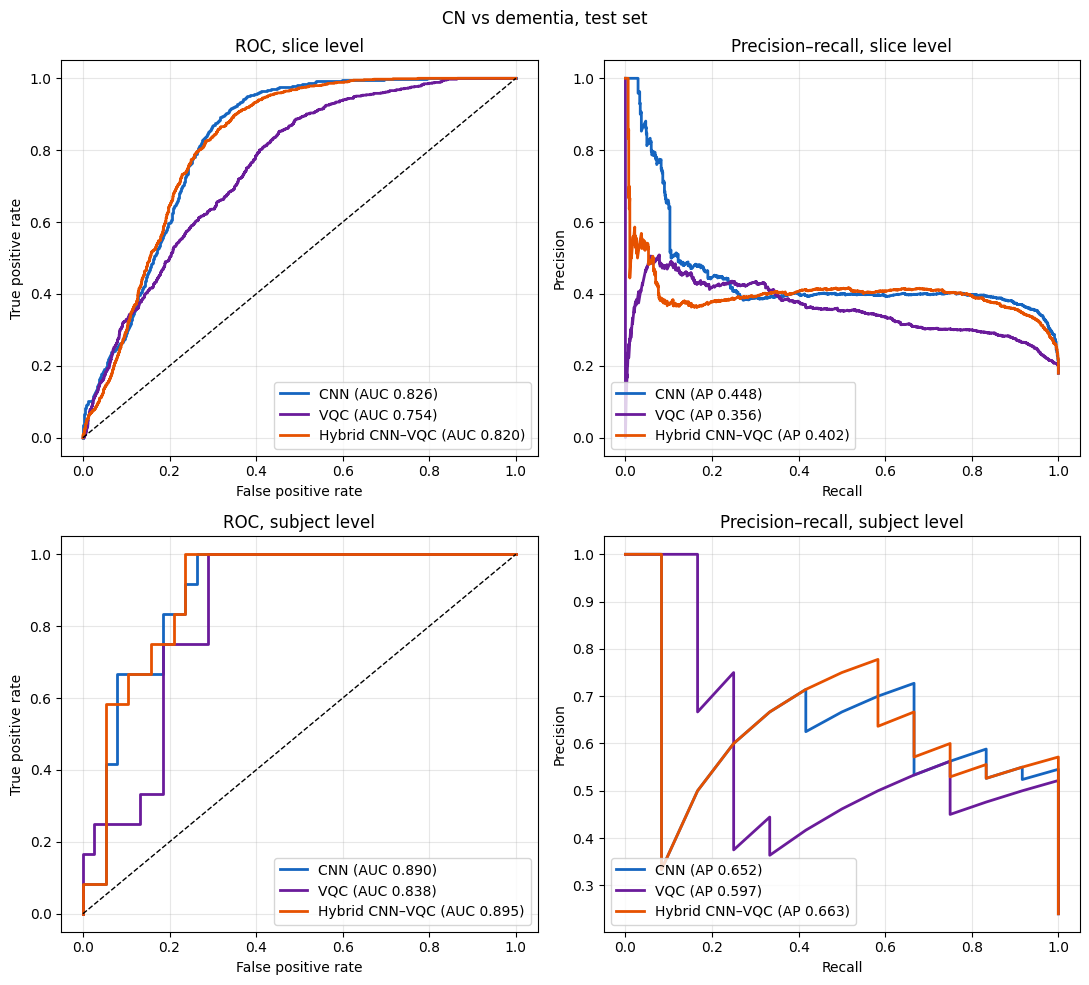

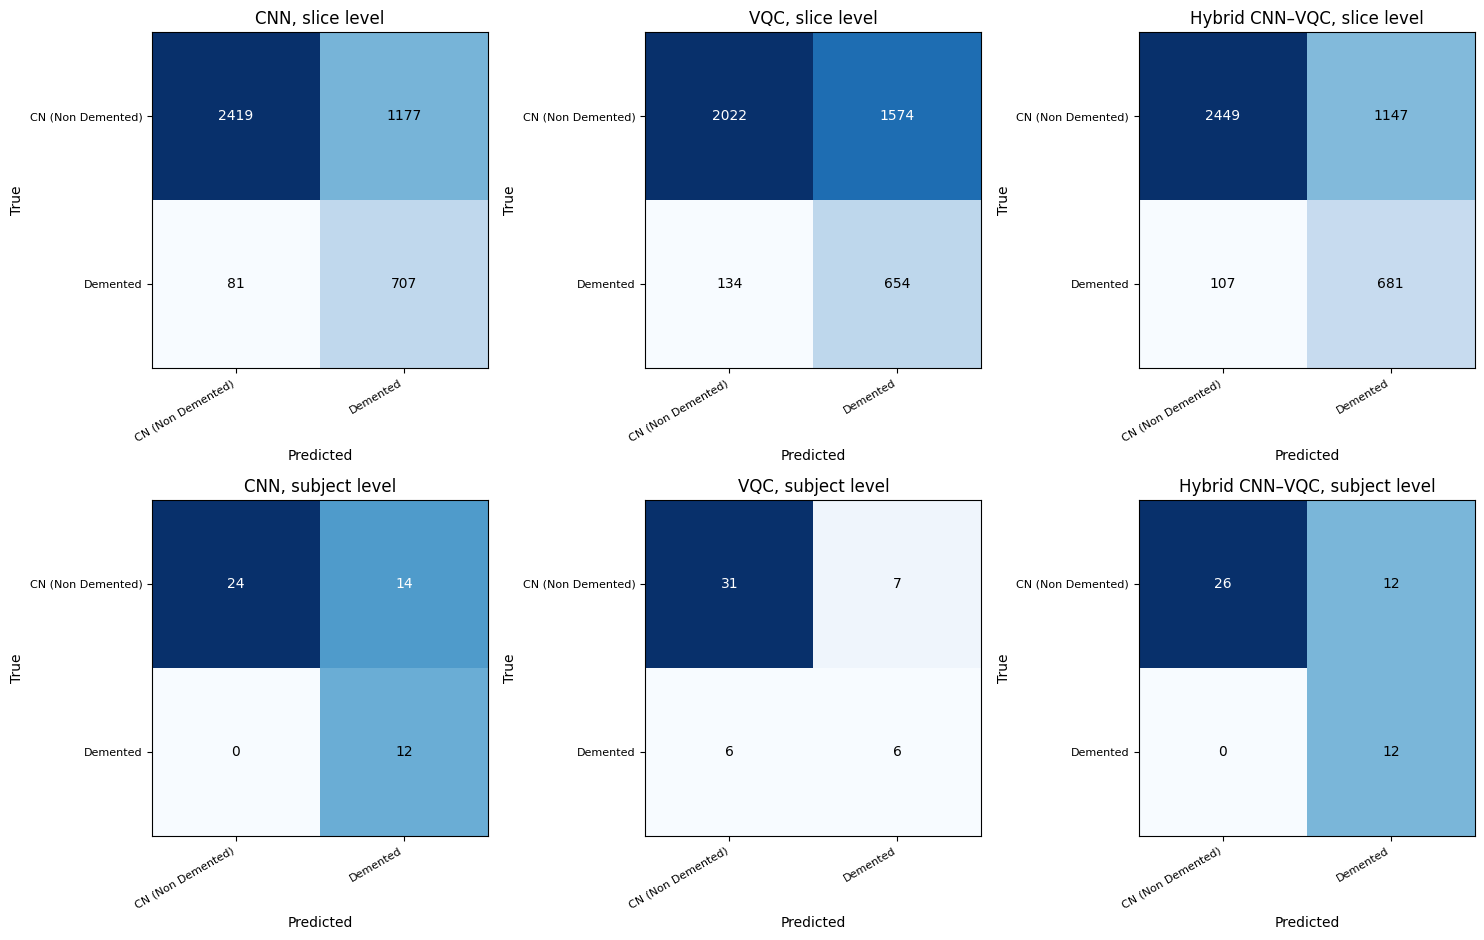

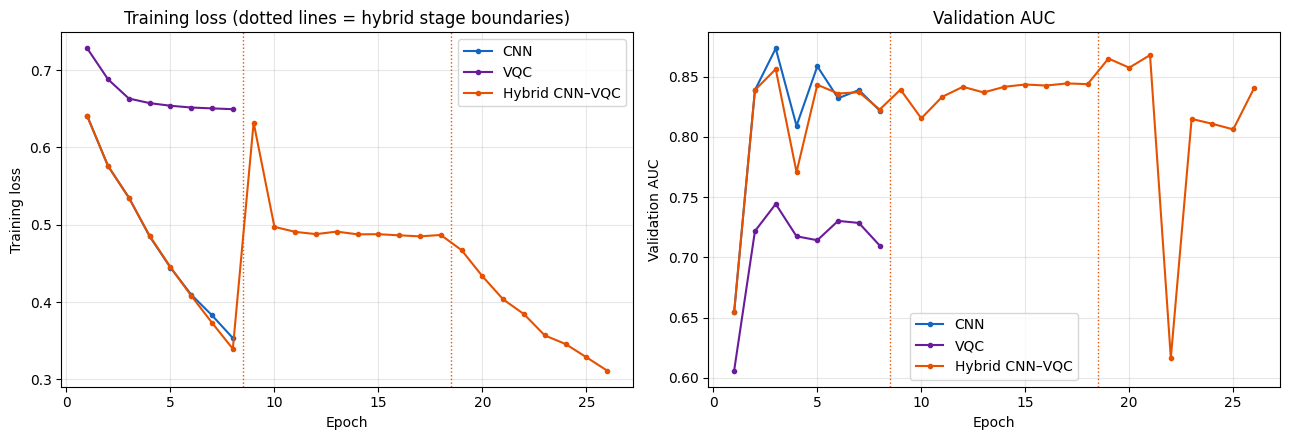

In [22]:
colors = {"CNN": "#1565C0", "VQC": "#6A1B9A", "Hybrid": "#E65100"}
fig, axes = plt.subplots(2, 2, figsize=(11, 10))
for r, level in enumerate(("slice", "subject")):
    for name in MODEL_NAMES:
        e = EVAL[(name, level)]
        y_bin = (e["y"] != 0).astype(int)            # CN vs dementia, valid for binary and 4-class
        score = 1 - e["probs"][:, 0]
        if len(np.unique(y_bin)) < 2:
            continue
        fpr, tpr, _ = roc_curve(y_bin, score)
        prec, rec, _ = precision_recall_curve(y_bin, score)
        axes[r, 0].plot(fpr, tpr, color=colors[name], lw=2,
                        label=f"{DISPLAY[name]} (AUC {roc_auc_score(y_bin, score):.3f})")
        axes[r, 1].plot(rec, prec, color=colors[name], lw=2,
                        label=f"{DISPLAY[name]} (AP {average_precision_score(y_bin, score):.3f})")
    axes[r, 0].plot([0, 1], [0, 1], "k--", lw=1)
    axes[r, 0].set(xlabel="False positive rate", ylabel="True positive rate", title=f"ROC, {level} level")
    axes[r, 1].set(xlabel="Recall", ylabel="Precision", title=f"Precision–recall, {level} level")
    for ax in axes[r]:
        ax.legend(loc="lower right" if ax is axes[r, 0] else "lower left"); ax.grid(alpha=0.3)
plt.suptitle("CN vs dementia, test set")
plt.tight_layout(); plt.savefig(OUT_DIR / "roc_pr_curves.png", dpi=300); plt.show()

fig, axes = plt.subplots(2, 3, figsize=(15, 9.5))
for r, level in enumerate(("slice", "subject")):
    for j, name in enumerate(MODEL_NAMES):
        e = EVAL[(name, level)]
        cm = confusion_matrix(e["y"], decide(e["probs"], e["thr"]), labels=list(range(N_CLASSES)))
        ax = axes[r, j]
        ax.imshow(cm, cmap="Blues")
        for i in range(N_CLASSES):
            for k in range(N_CLASSES):
                ax.text(k, i, cm[i, k], ha="center", va="center",
                        color="white" if cm[i, k] > cm.max() / 2 else "black")
        ax.set_xticks(range(N_CLASSES)); ax.set_yticks(range(N_CLASSES))
        ax.set_xticklabels(CLASS_NAMES, rotation=30, ha="right", fontsize=8)
        ax.set_yticklabels(CLASS_NAMES, fontsize=8)
        ax.set(xlabel="Predicted", ylabel="True", title=f"{DISPLAY[name]}, {level} level")
plt.tight_layout(); plt.savefig(OUT_DIR / "confusion_matrices.png", dpi=300); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for name in MODEL_NAMES:
    h = HIST[(name, SEEDS[0])]
    axes[0].plot(h.epoch, h.train_loss, "o-", ms=3, color=colors[name], label=DISPLAY[name])
    axes[1].plot(h.epoch, h.val_auc, "o-", ms=3, color=colors[name], label=DISPLAY[name])
h = HIST[("Hybrid", SEEDS[0])]
for ax in axes:
    for stage_end in h.groupby("stage", sort=False).epoch.max().values[:-1]:
        ax.axvline(stage_end + 0.5, color=colors["Hybrid"], ls=":", lw=1)
    ax.set_xlabel("Epoch"); ax.grid(alpha=0.3); ax.legend()
axes[0].set_ylabel("Training loss"); axes[1].set_ylabel("Validation AUC")
axes[0].set_title("Training loss (dotted lines = hybrid stage boundaries)"); axes[1].set_title("Validation AUC")
plt.tight_layout(); plt.savefig(OUT_DIR / "training_curves.png", dpi=300); plt.show()

## 15. Grad-CAM

Grad-CAM on the last convolutional block. For the hybrid model the gradient flows back through the
quantum circuit, so the heatmap reflects what drives the hybrid's quantum-processed decision.

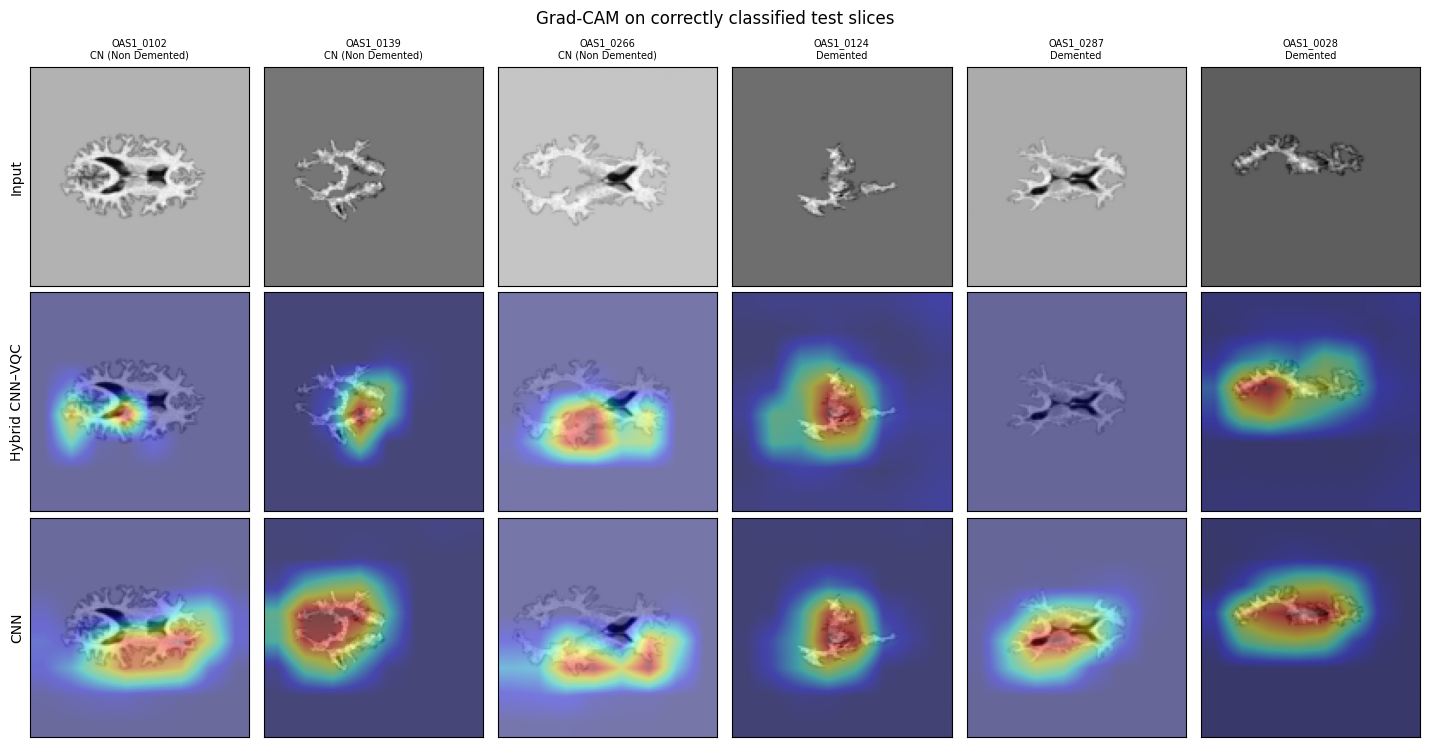

In [23]:
class GradCAM:
    def __init__(self, model, layer):
        self.model, self.acts, self.grads = model, None, None
        self.handle = layer.register_forward_hook(self._hook)

    def _hook(self, module, inputs, output):
        self.acts = output
        output.register_hook(lambda g: setattr(self, "grads", g))

    def __call__(self, x, target=None):
        self.model.eval(); self.model.zero_grad(set_to_none=True)
        logits = self.model(x.to(DEVICE))
        target = logits.argmax(1) if target is None else target.to(logits.device)
        logits.gather(1, target[:, None]).sum().backward()
        w = self.grads.mean(dim=(2, 3), keepdim=True)
        cam = F.relu((w * self.acts).sum(1, keepdim=True))
        cam = F.interpolate(cam, size=x.shape[-2:], mode="bilinear", align_corners=False).squeeze(1)
        cam = cam / (cam.flatten(1).max(1)[0][:, None, None] + 1e-8)
        return cam.detach().cpu().numpy(), torch.softmax(logits, 1).detach().cpu().numpy()

    def remove(self):
        self.handle.remove()

if RUN_GRADCAM:
    ds_te = SliceDataset(DF["test"])
    p_h = PROBS["Hybrid"]["test"][0]
    correct = np.where(p_h.argmax(1) == DF["test"].label.values)[0]
    rng = np.random.RandomState(0)
    picks = []
    for c in range(N_CLASSES):
        cand = correct[DF["test"].label.values[correct] == c]
        picks += list(rng.choice(cand, min(3, len(cand)), replace=False)) if len(cand) else []
    if picks:
        x = torch.stack([ds_te[i][0] for i in picks])
        ch = x.shape[1] // 2
        cams = {}
        for name in ("Hybrid", "CNN"):
            gc = GradCAM(TRAINED[name], TRAINED[name].backbone.features[-1])
            cams[name], _ = gc(x)
            gc.remove()
        fig, axes = plt.subplots(3, len(picks), figsize=(2.4 * len(picks), 7.6))
        axes = np.array(axes).reshape(3, -1)
        for j, i in enumerate(picks):
            img = x[j, ch].numpy()
            axes[0, j].imshow(img, cmap="gray")
            axes[0, j].set_title(f"{DF['test'].subject[i]}\n{CLASS_NAMES[DF['test'].label[i]]}", fontsize=7)
            for r, name in ((1, "Hybrid"), (2, "CNN")):
                axes[r, j].imshow(img, cmap="gray")
                axes[r, j].imshow(cams[name][j], cmap="jet", alpha=0.4)
        for ax in axes.ravel():
            ax.set_xticks([]); ax.set_yticks([])
        axes[0, 0].set_ylabel("Input"); axes[1, 0].set_ylabel("Hybrid CNN–VQC"); axes[2, 0].set_ylabel("CNN")
        plt.suptitle("Grad-CAM on correctly classified test slices")
        plt.tight_layout(); plt.savefig(OUT_DIR / "gradcam.png", dpi=300); plt.show()

## 16. Optional: external validation on ADNI

Expects `ADNI_DIR/AD/*.nii(.gz)` and `ADNI_DIR/CN/*.nii(.gz)`. Axial slices are taken from the same relative
band of the brain and pass through the identical preprocessing. The models trained on OASIS are applied
unchanged (all seeds, probability-averaged), with the dementia score `1 − p(CN)` and the OASIS-validation
threshold.

Raw ADNI scans are not registered to the same template as the OASIS images, so check the orientation
montage below. Ideally register ADNI to the same atlas first; report any remaining domain shift.

In [24]:
if RUN_ADNI:
    import nibabel as nib
    ADNI_RE = re.compile(r"\d{3}_S_\d{4}")

    def adni_slices(path):
        vol = nib.as_closest_canonical(nib.load(str(path))).get_fdata().astype(np.float32)
        hi = np.percentile(vol, 99.5)
        vol = np.clip(vol / (hi + 1e-6), 0, 1) * 255.0                 # same 0-255 range as the JPEG slices
        thr = threshold_otsu(vol[vol > 0]) if (vol > 0).sum() > 100 else 0
        area = (vol > thr).mean(axis=(0, 1))
        idx = np.where(area > 0.02)[0]                                   # axial slices containing head
        a, b = SLICE_FRACTION_RANGE
        lo, hi_ = idx[0] + int(a * (len(idx) - 1)), idx[0] + int(b * (len(idx) - 1))
        load = list(range(max(lo - 1, 0), min(hi_ + 1, vol.shape[2] - 1) + 1))
        imgs = [np.rot90(vol[:, :, k]) for k in load]                    # radiological axial view
        center = [i for i, k in enumerate(load) if lo <= k <= hi_]
        return imgs, center

    adni_rows, ADNI_VOLS = [], {}
    for cls, lab in (("CN", 0), ("AD", 1)):
        for f in sorted((Path(ADNI_DIR) / cls).rglob("*.nii*")):
            m = ADNI_RE.search(str(f))
            subj = m.group(0) if m else f.stem
            scan_id = f"{cls}_{f.name}"
            imgs, center = adni_slices(f)
            vol, qc = preprocess_slices(imgs)
            ADNI_VOLS[scan_id] = vol
            adni_rows += [(scan_id, k, k, subj, lab) for k in center if qc[k]]
    df_adni = pd.DataFrame(adni_rows, columns=["scan", "pos", "slice", "subject", "label"])
    VOLUMES.update(ADNI_VOLS)
    print(df_adni.groupby("label").agg(subjects=("subject", "nunique"), slices=("slice", "size")))

    show = list(ADNI_VOLS)[:6]
    fig, axes = plt.subplots(1, len(show), figsize=(2.4 * len(show), 2.6))
    for ax, s in zip(np.atleast_1d(axes), show):
        v = ADNI_VOLS[s]; ax.imshow(v[len(v) // 2].astype(np.float32), cmap="gray"); ax.set_title(s[:18], fontsize=7); ax.axis("off")
    plt.suptitle("ADNI after preprocessing: check orientation matches OASIS"); plt.tight_layout(); plt.show()

    dl_adni = DataLoader(SliceDataset(df_adni), batch_size=BATCH_SIZE * 2, shuffle=False, num_workers=NUM_WORKERS)
    adni_rows_out = []
    for name in MODEL_NAMES:
        probs = []
        for sd in SEEDS:
            m = to_device(MODEL_BUILDERS[name](N_CLASSES, HP[name]["dropout"]))
            m.load_state_dict(torch.load(OUT_DIR / f"{name}_seed{sd}.pt", map_location="cpu"))
            to_device(m)
            probs.append(predict(m, dl_adni))
        p = np.mean(probs, axis=0)
        p_bin = np.stack([p[:, 0], 1 - p[:, 0]], 1)                     # CN vs dementia
        for level in ("slice", "subject"):
            if level == "slice":
                y, pp, g = df_adni.label.values, p_bin, df_adni.subject.values
            else:
                y, pp, g = subject_level(df_adni, p_bin)
            thr = EVAL[(name, level)]["thr"] if N_CLASSES == 2 else 0.5
            mtr = compute_metrics(y, pp, thr)
            ci = bootstrap_ci(y, pp, g, thr)
            adni_rows_out.append({"Model": DISPLAY[name], "Level": level, "n": len(y),
                                  **{k: fmt(v, ci.get(k), pct=(k != "AUC")) for k, v in mtr.items()}})
    adni_results = pd.DataFrame(adni_rows_out)
    adni_results.to_csv(OUT_DIR / "adni_external_validation.csv", index=False)
    print("ADNI external validation (trained on OASIS only):")
    print(adni_results.to_string(index=False))

## 17. Saved outputs

In [25]:
for p in sorted(OUT_DIR.iterdir()):
    print(f"{p.name:40s} {p.stat().st_size / 1024:8.1f} KB")

CNN_seed42.pt                              4610.2 KB
Hybrid_seed42.pt                           4622.0 KB
VQC_seed42.pt                                10.7 KB
complexity_table.csv                          0.3 KB
confusion_matrices.png                      255.1 KB
gradcam.png                                 323.9 KB
hyperparameters.json                          0.6 KB
preprocessing_examples.png                  558.2 KB
probabilities.npz                           226.0 KB
results_full.csv                              7.0 KB
results_table.csv                             2.0 KB
roc_pr_curves.png                           525.7 KB
split_samples.csv                          1389.2 KB
statistical_tests.csv                         0.4 KB
training_curves.png                         290.5 KB
training_history.csv                          4.2 KB


### Reporting checklist
* State the split unit (subject), the averaging method (macro) and whether results are slice- or subject-level.
* Report the tuned threshold and that it was chosen on the validation set only.
* Report the McNemar and AUC-difference results; if the hybrid–CNN difference is not significant, describe the
  models as comparable and support the hybrid with the complexity table and ADNI results.
* Update the methodology flowchart and text to describe exactly the steps run here.